# What does it mean for a model to understand time? Numerical illustrations

This notebook accompanies the report and illustrates its definitions and results on synthetic scenes. No model is trained; the experiments isolate each mechanism in a controlled setting.

**Observer.** The observer has no access to equations of motion. Its knowledge of each object class is a bank of clips recorded at natural speed. A motion is plausible to the extent that it is close to a clip of the bank; the gap $d_L$ of Def. 2, the root-mean-square distance between two motions over a window of length $L$, is estimated by averaging over frames and minimised over the clips of the bank, their start times and positions.

**Notation.** World time $s$, playback time $t$, clock $s=\tau(t)$; a constant clock is $s=\alpha t$ ($\alpha<1$ in slow motion); a distortion applied to a clip is $s=ct$; $\varepsilon$ is the tolerance below which a distortion is considered invisible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, Markdown, display
from scipy import stats

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "animation.embed_limit": 100})
rng = np.random.default_rng(0)
FPS = 25                    # playback rate of the videos, known to the observer
FINE = 100                  # resolution at which bank clips are stored (Hz)

def show(fig, update, n_frames, fps=FPS):
    """Play an animation inside the notebook (works in VS Code, no ffmpeg needed)."""
    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000/fps)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode="loop"))

## 0. Objects and experience

Five object classes are used. Two follow rules defined for this notebook, so that time-rigidity cannot be attributed to physical knowledge.

| class | motion | temporal behaviour |
|---|---|---|
| walker | leg angle of amplitude $A$ at cadence $f(A)=0.5+2A$ | time-rigid: the stride determines the cadence |
| looper | circle of radius $r$ at angular speed $h(r)=3/r$ | time-rigid |
| snail | straight line at a speed drawn from a broad law | time-elastic |
| ball | ballistic trajectory | time-rigid, reversible |
| fader | damped oscillation | irreversible |

Each bank contains 120 clips at natural speed with random shape parameters. `closest_plausible` returns the gap $d_L$ to the nearest clip, over all start times and translations; positions are centred, since location carries no temporal information.

In [2]:
f_walk = lambda A: 0.5 + 2.0*A                      # invented rule: stride -> cadence (Hz)
h_loop = lambda r: 3.0/r                            # invented rule: radius -> angular speed (rad/s)

def walker(s, A, ph=0.0):   return np.stack([A*np.sin(2*np.pi*f_walk(A)*s + ph), 0*s], -1)
def looper(s, r, ph=0.0):   return np.stack([r*np.cos(h_loop(r)*s + ph), r*np.sin(h_loop(r)*s + ph)], -1)
def snail(s, v):            return np.stack([v*s, 0*s], -1)
def ball(s, vx, vy):        return np.stack([vx*s, vy*s - 0.5*9.81*s**2], -1)
def fader(s, a, w):         return np.stack([a*np.exp(-0.8*s)*np.cos(w*s), 0*s], -1)

TB = 3.5                                            # length of each bank clip (s)
sb = np.arange(0, TB, 1/FINE)                       # fine time grid of the bank
def make_bank(n=120):
    return {
        "walker": np.array([walker(sb, A, ph) for A, ph in zip(rng.uniform(0.1, 0.8, n), rng.uniform(0, 2*np.pi, n))]),
        "looper": np.array([looper(sb, r, ph) for r, ph in zip(rng.uniform(0.4, 1.0, n), rng.uniform(0, 2*np.pi, n))]),
        "snail":  np.array([snail(sb, v) for v in np.exp(rng.normal(np.log(0.3), 0.6, n))]),
        "ball":   np.array([ball(sb, vx, vy) for vx, vy in zip(rng.choice([-1, 1], n)*rng.uniform(0.5, 2, n), rng.uniform(2, 8, n))]),
        "fader":  np.array([fader(sb, a, w) for a, w in zip(rng.uniform(0.5, 1, n), rng.uniform(4, 12, n))]),
    }
BANK = make_bank()

def closest_plausible(t, w, bank):
    """Nearest natural-speed clip in the bank, over all start times and positions.
    t: frame times of the window (multiples of 1/FPS), w: positions seen, shape (K, 2).
    Returns (gap d_L, the plausible window)."""
    step = int(round((t[1] - t[0])*FINE)) if len(t) > 1 else 1
    idx = np.round((t - t[0])*FINE).astype(int)                     # frame positions in the fine grid
    offsets = np.arange(0, len(sb) - idx[-1], 2)                    # candidate start times
    win = bank[:, offsets[:, None] + idx[None, :], :]               # (N, offsets, K, 2)
    win = win - win.mean(2, keepdims=True)                          # positions are free (translation)
    wc = w - w.mean(0)
    g = np.sqrt(np.mean(np.sum((win - wc)**2, -1), -1))             # mean gap for every candidate
    n, o = np.unravel_index(np.argmin(g), g.shape)
    return g[n, o], win[n, o] + w.mean(0)

## 1. A video reveals the path, not the clock (Prop. 2)

A looper is filmed under a clock running twice too fast (left), and a looper turning twice as fast is filmed under the natural clock (right). The two sequences coincide frame by frame (maximum difference 0). The frames therefore do not determine the clock; only prior knowledge of plausible angular speeds can separate the two scenes, which motivates the plausibility-based definitions that follow.

In [3]:
t = np.arange(0, 2, 1/FPS)
left  = looper(2*t, 0.7)                                   # clock x2
right = np.stack([0.7*np.cos(2*h_loop(0.7)*t), 0.7*np.sin(2*h_loop(0.7)*t)], -1)   # object x2
display(Markdown(f"Largest difference between the two videos: ${np.abs(left - right).max():.1f}$."))
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
dots = []
for ax, title in zip(axes, ["clock x2", "object x2"]):
    ax.add_patch(plt.Circle((0, 0), 0.7, fill=False, color="0.85")); ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=9)
    dots.append(ax.plot([], [], "o", ms=9)[0])
def update(k):
    dots[0].set_data([left[k, 0]], [left[k, 1]]); dots[1].set_data([right[k, 0]], [right[k, 1]])
show(fig, update, len(t))

Largest difference between the two videos: $0.0$.

## 2. Time-rigid and time-elastic objects (Def. 1)

A distortion changes the speed at which a curve is drawn, not the curve. We compare, for each class, a slowed-down video with an object that is genuinely slower. For the walker, a slower individual has a smaller stride, since stride and cadence are coupled; the slowed video instead preserves the stride at half the cadence, a combination absent from experience, so the distortion is detectable. For the snail, both coincide: the class is time-elastic and the overall playback speed is not observable.

The forward displacement of the walker (stride times cadence) is used for rendering only; unless stated otherwise, the observer sees the leg angle.

In [4]:
A0 = 0.7; A_slow = (f_walk(A0)/2 - 0.5)/2.0                # stride of a walker with half the cadence
v0 = 0.4
LEG = 0.5
def draw_walker(ax, theta, x):
    hip = np.array([x, 1.0])
    for sgn in (1, -1):
        foot = hip + LEG*np.array([np.sin(sgn*theta), -np.cos(sgn*theta)])
        ax.plot([hip[0], foot[0]], [hip[1], foot[1]], c="k", lw=2)
    ax.plot([x, x], [1, 1.5], c="k", lw=2); ax.plot(x, 1.6, "o", c="k", ms=6)
speed = lambda A: 4*LEG*np.sin(A)*f_walk(A)               # forward speed implied by stride and cadence
cols = [("natural", A0, 1.0), ("slowed video x2", A0, 0.5), ("slower walker", A_slow, 1.0)]
t = np.arange(0, 3, 1/FPS)
fig, axes = plt.subplots(2, 3, figsize=(8, 3.6))
def update(k):
    for j, (title, A, rate) in enumerate(cols):
        ax = axes[0, j]; ax.clear(); ax.axis("off"); ax.set_xlim(-0.5, 6); ax.set_ylim(-0.1, 1.9); ax.set_aspect("equal")
        s = rate*t[k]; draw_walker(ax, A*np.sin(2*np.pi*f_walk(A)*s), speed(A)*s); ax.plot([-0.5, 6], [0.05, 0.05], c="0.7")
        ax.set_title(title, fontsize=9)
        ax = axes[1, j]; ax.clear(); ax.axis("off"); ax.set_xlim(-0.1, 1.3); ax.set_ylim(-0.2, 0.3)
        v = v0*(0.5 if j > 0 else 1.0)
        ax.add_patch(plt.Circle((v*t[k], 0.08), 0.07, color="C1")); ax.plot([-0.1, 1.3], [0, 0], c="0.7")
    axes[1, 0].set_title("snail, natural", fontsize=8); axes[1, 1].set_title("snail, slowed video", fontsize=8); axes[1, 2].set_title("slower snail", fontsize=8)
show(fig, update, len(t))

## 3. Quasi-rigidity (Def. 2, Prop. 1)

We compute $d_L$ between a distorted clip and its nearest plausible clip, for distortions $c\in[0.5,2]$ and windows $L\in[0.12,1.2]$ s, for a walker ($A=0.5$) and a snail. Colour encodes $\log_{10}d_L$; the white contour is $d_L=\varepsilon$.

For the walker, no distortion is detectable on short windows, in agreement with Prop. 1; the detectable region widens with $L$, and at $L\approx1$ s distortions of a few percent are resolved. Strong slow motion ($c=0.5$) requires about 0.7 s, since a short segment of a slow, wide oscillation is matched by part of another walker's cycle. For the snail, $d_L<\varepsilon$ throughout; the horizontal stripes reflect the finite set of speeds in the bank.

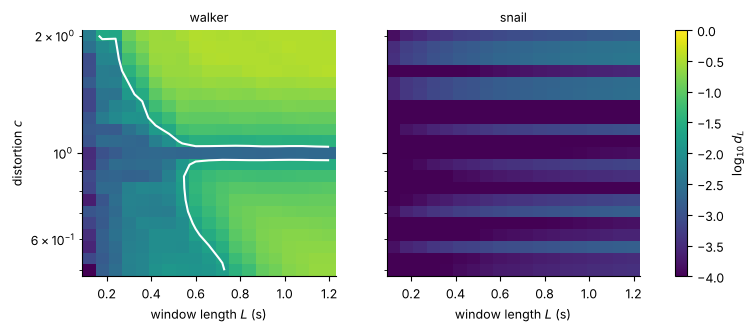

In [5]:
EPS = 0.02
def seen_gap(path, c, L, fps=FPS, bank=None):
    t = np.arange(0, L, 1/fps)
    return closest_plausible(t, path(c*t), bank)[0]

cs = np.exp(np.linspace(np.log(0.5), np.log(2.0), 21))
Ls = np.linspace(0.12, 1.2, 19)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, path) in zip(axes, [("walker", lambda s: walker(s, 0.5)), ("snail", lambda s: snail(s, 0.3))]):
    D = np.array([[seen_gap(path, c, L, bank=BANK[name]) for L in Ls] for c in cs])
    im = ax.pcolormesh(Ls, cs, np.log10(np.maximum(D, 1e-4)), cmap="viridis", vmin=-4, vmax=0, shading="auto")
    if D.max() > EPS: ax.contour(Ls, cs, D, levels=[EPS], colors="w", linewidths=1.5)
    ax.set_yscale("log"); ax.set_xlabel(r"window length $L$ (s)"); ax.set_title(name, fontsize=9)
axes[0].set_ylabel(r"distortion $c$")
fig.colorbar(im, ax=axes, label=r"$\log_{10} d_L$"); plt.show()

### Dependence on the observed variables

The same walker is presented to three observers whose banks contain the same individuals observed in the same way: body position only, leg angle only, or both. The body alone, translating at constant speed, is time-elastic. The leg angle makes the walker time-rigid through the stride–cadence coupling. Observing both adds the constraint that forward speed must match the stride, which moves the detection boundary to shorter windows. Rigidity is thus a property of the observation as much as of the object.

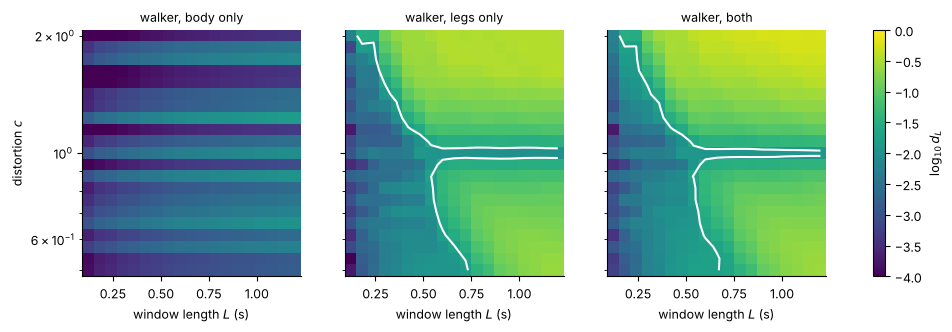

In [6]:
def walker_body(s, A, ph=0.0): return np.stack([0*s, speed(A)*s], -1)
def walker_both(s, A, ph=0.0): return np.stack([A*np.sin(2*np.pi*f_walk(A)*s + ph), speed(A)*s], -1)
A_b, ph_b = rng.uniform(0.1, 0.8, 120), rng.uniform(0, 2*np.pi, 120)
views = {"body only": (walker_body, np.array([walker_body(sb, A, p) for A, p in zip(A_b, ph_b)])),
         "legs only": (walker,      np.array([walker(sb, A, p) for A, p in zip(A_b, ph_b)])),
         "both":      (walker_both, np.array([walker_both(sb, A, p) for A, p in zip(A_b, ph_b)]))}
cs = np.exp(np.linspace(np.log(0.5), np.log(2.0), 21))
Ls = np.linspace(0.12, 1.2, 19)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (name, (view, bank)) in zip(axes, views.items()):
    D = np.array([[seen_gap(lambda s: view(s, 0.5), c, L, bank=bank) for L in Ls] for c in cs])
    im = ax.pcolormesh(Ls, cs, np.log10(np.maximum(D, 1e-4)), cmap="viridis", vmin=-4, vmax=0, shading="auto")
    if D.max() > EPS: ax.contour(Ls, cs, D, levels=[EPS], colors="w", linewidths=1.5)
    ax.set_yscale("log"); ax.set_xlabel(r"window length $L$ (s)"); ax.set_title(f"walker, {name}", fontsize=9)
axes[0].set_ylabel(r"distortion $c$")
fig.colorbar(im, ax=axes, label=r"$\log_{10} d_L$"); plt.show()

### Invariance to the frame rate

The same slowed walker ($c=0.8$) is sampled at 10, 25 and 100 frames per second. The gap $d_L$, defined as a mean over the window, is invariant up to discretisation effects at 10 fps, whereas a distance summed over frames scales with their number. Additional frames improve the estimate of $d_L$ and average out noise; they do not change the rigidity of the motion.

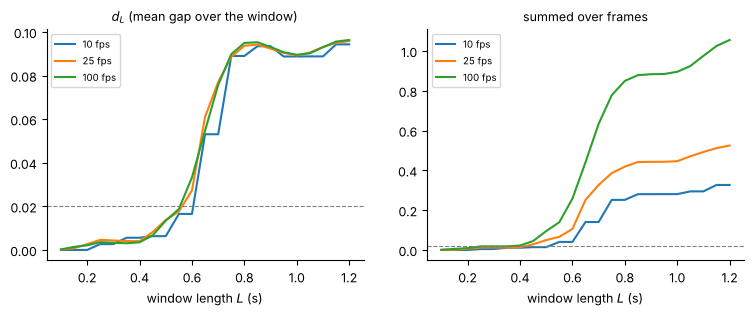

In [7]:
Ls = np.linspace(0.1, 1.2, 23)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for fps in [10, 25, 100]:
    g = np.array([seen_gap(lambda s: walker(s, 0.5), 0.8, L, fps, BANK["walker"]) for L in Ls])
    K = np.array([len(np.arange(0, L, 1/fps)) for L in Ls])
    axes[0].plot(Ls, g, label=f"{fps} fps"); axes[1].plot(Ls, g*np.sqrt(K), label=f"{fps} fps")
axes[0].set_title(r"$d_L$ (mean gap over the window)", fontsize=9); axes[1].set_title("summed over frames", fontsize=9)
for ax in axes: ax.axhline(EPS, c="0.5", ls="--", lw=.8); ax.set_xlabel(r"window length $L$ (s)"); ax.legend(fontsize=7)
plt.show()

### Estimating $\rho$

We draw 120 walkers from the population $\pi$ (stride uniform in $[0.1,0.8]$, random phase), slow each by $c=0.8$ and compute $d_L$ for three window lengths. The fraction below $\varepsilon$ estimates $\rho$ in Def. 2: $\rho=1$ at $L=0.2$ s, about 0.5 at $0.5$ s and below 0.2 at $1$ s. Small strides remain ambiguous: a slowed walker of stride $A$ has the cadence of a natural walker of stride $0.8A-0.05$, a discrepancy $0.2A+0.05$ that vanishes with $A$. The dispersion reflects the random phase and the finite bank.

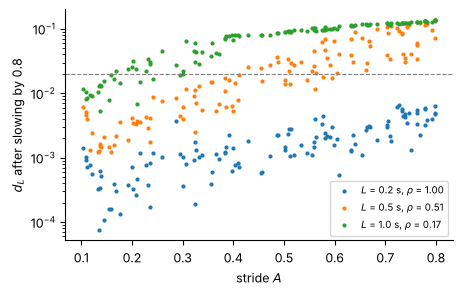

In [8]:
A_pop = rng.uniform(0.1, 0.8, 120)
fig, ax = plt.subplots(figsize=(5, 3))
for L in [0.2, 0.5, 1.0]:
    d = np.array([seen_gap(lambda s, A=A: walker(s, A, rng.uniform(0, 6)), 0.8, L, bank=BANK["walker"]) for A in A_pop])
    o = np.argsort(A_pop)
    ax.plot(A_pop[o], d[o], ".", ms=4, label=fr"$L$ = {L} s, $\rho$ = {np.mean(d <= EPS):.2f}")
ax.axhline(EPS, c="0.5", ls="--", lw=.8); ax.set_yscale("log")
ax.set_xlabel(r"stride $A$"); ax.set_ylabel(r"$d_L$ after slowing by 0.8"); ax.legend(fontsize=7); plt.show()

### Dependence on experience

We vary the bank size from 2 to 120 walkers and evaluate, on 60 new walkers observed for 0.6 s, how well $d_L$ separates slowed clips ($c=0.8$) from natural ones, using the area under the ROC curve. Separation increases from near chance to about 0.9. With a small bank, natural clips are themselves far from all exemplars, so $d_L$ measures novelty rather than distortion. Rigidity is therefore acquired: it presupposes an association between trajectories and speeds learned from natural-rate data. The AUC is used instead of a fixed $\varepsilon$, which is not meaningful for small banks; the estimate is noisy (60 test walkers, one bank).

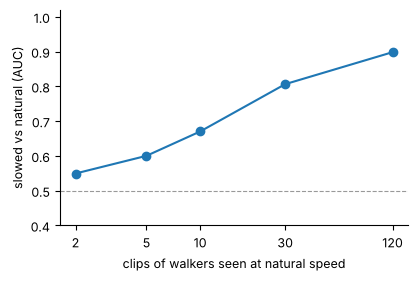

In [9]:
def auc(pos, neg): return np.mean(pos[:, None] > neg[None, :]) + 0.5*np.mean(pos[:, None] == neg[None, :])
sizes = [2, 5, 10, 30, 120]
res = []
for n in sizes:
    bank = BANK["walker"][:n]
    tests = rng.uniform(0.1, 0.8, 60)
    nat = np.array([seen_gap(lambda s, A=A: walker(s, A, rng.uniform(0, 6)), 1.0, 0.6, bank=bank) for A in tests])
    slo = np.array([seen_gap(lambda s, A=A: walker(s, A, rng.uniform(0, 6)), 0.8, 0.6, bank=bank) for A in tests])
    res.append(auc(slo, nat))
fig, ax = plt.subplots(figsize=(4.5, 2.8))
ax.plot(sizes, res, "o-"); ax.set_xscale("log"); ax.set_xticks(sizes); ax.set_xticklabels(sizes); ax.minorticks_off()
ax.axhline(0.5, c="0.6", ls="--", lw=.8); ax.set_ylim(0.4, 1.02)
ax.set_xlabel("clips of walkers seen at natural speed"); ax.set_ylabel("slowed vs natural (AUC)"); plt.show()

## 4. Sequential detection

Each row shows a clip and its nearest plausible clip, refitted at every frame on the data observed so far, together with the evolution of $d_L$ and the decision threshold.

| scenario | outcome | result |
|---|---|---|
| walker, slowed ×2 | detected after ≈0.7 s | Prop. 1 |
| snail, slowed ×2 | never detected | Cor. 4(i) |
| snail, slow motion from mid-clip | detected after the change | Cor. 4(i): the clock is known up to a factor |
| ball, reversed | not detected | reversibility |
| fader, reversed | detected | Cor. 4(iii) |

In [10]:
T = 1.2
t = np.arange(0, T, 1/FPS)
cases = [  # (title, path, clock, bank, axis limits)
    ("walker, slowed x2",          lambda s: walker(s, 0.5),        lambda t: 0.5*t, "walker", ((-0.7, 0.7), (-0.3, 0.3))),
    ("snail, slowed x2",           lambda s: snail(s, 0.8),         lambda t: 0.5*t, "snail",  ((-0.05, 1.0), (-0.1, 0.1))),
    ("snail, slow motion mid-video", lambda s: snail(s, 0.8),      lambda t: np.where(t < T/3, t, T/3 + 0.15*(t - T/3)), "snail", ((-0.05, 1.0), (-0.1, 0.1))),
    ("ball, reversed",             lambda s: ball(s, 1.2, 5.0),     lambda t: 1.0 - t, "ball",   ((-0.2, 1.4), (-1.5, 1.5))),
    ("fader, reversed",            lambda s: fader(s, 0.8, 8.0),    lambda t: 1.6 - t, "fader",  ((-2.5, 2.5), (-0.3, 0.3))),
]
gaps = np.zeros((len(cases), len(t)))
fits = []
for i, (_, q, tau, b, _) in enumerate(cases):
    w = q(tau(t)); fit_k = []
    for k in range(len(t)):
        if k < 2: gaps[i, k] = 1e-4; fit_k.append(w[k]); continue
        g, f = closest_plausible(t[:k+1], w[:k+1], BANK[b]); gaps[i, k] = max(g, 1e-4); fit_k.append(f[-1])
    fits.append((w, np.array(fit_k)))

fig, axes = plt.subplots(len(cases), 2, figsize=(8, 1.7*len(cases)), gridspec_kw=dict(width_ratios=[1.5, 1]))
art = []
for i, (title, _, _, _, (xl, yl)) in enumerate(cases):
    ax, axr = axes[i]
    ax.set_xlim(*xl); ax.set_ylim(*yl); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8, loc="left")
    tr, = ax.plot([], [], ".", c="C0", ms=2, alpha=.5)
    ob, = ax.plot([], [], "o", c="C0", ms=7, label="seen")
    gh, = ax.plot([], [], "o", c="C3", ms=7, alpha=.45, label="closest in bank")
    tx = ax.text(0.98, 0.78, "", transform=ax.transAxes, ha="right", fontsize=8)
    axr.set_xlim(0, T); axr.set_ylim(1e-4, 2); axr.set_yscale("log"); axr.axhline(EPS, c="0.5", ls="--", lw=.8)
    axr.tick_params(labelsize=6); axr.set_ylabel(r"$d_L$", fontsize=7)
    rs, = axr.plot([], [], c="C3")
    if i == 0: ax.legend(fontsize=6, loc="upper left")
    art.append((tr, ob, gh, tx, rs))
axes[-1, 1].set_xlabel("playback time (s)", fontsize=7)
plt.tight_layout()
def update(k):
    for i in range(len(cases)):
        tr, ob, gh, tx, rs = art[i]; w, f = fits[i]
        tr.set_data(w[:k+1, 0], w[:k+1, 1]); ob.set_data([w[k, 0]], [w[k, 1]]); gh.set_data([f[k, 0]], [f[k, 1]])
        rs.set_data(t[:k+1], gaps[i, :k+1])
        ok = gaps[i, k] < EPS
        tx.set_text("plausible" if ok else "distorted"); tx.set_color("C2" if ok else "C3")
show(fig, update, len(t), fps=FPS//2)

## 5. The clock of the scene (Prop. 3, Cor. 4(ii))

A scene recorded at $\alpha=0.5$ contains a walker and a snail. For each candidate clock, the clip is re-timed and compared with each bank. The snail alone yields a broad posterior over $\alpha$, determined by the distribution of plausible snail speeds (the typical answer). The walker yields a sharp likelihood; since the clock is shared, the scene posterior is their product. The estimated clock is 0.49 and the snail's speed, deduced from it, is 0.356 m/s (true value 0.35), although the snail alone does not determine it.

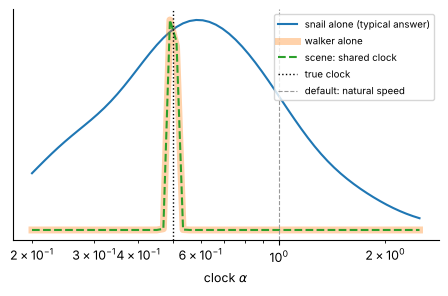

Clock read on the scene: $\hat\alpha=0.49$ (true $0.5$). Snail speed deduced: $0.356$ m/s (true $0.35$).

In [11]:
alpha_true, L = 0.5, 1.2
t = np.arange(0, L, 1/FPS)
walk_seen  = walker(alpha_true*t, 0.6, 0.3)
snail_seen = snail(alpha_true*t, 0.35)
alphas = np.exp(np.linspace(np.log(0.2), np.log(2.5), 60))
def fit_under_clock(seen, a, bank):           # re-time the video with clock a and compare with experience
    s_frames = a*t                            # world times of the frames under this clock
    w = seen
    # bank clips evaluated at the same world times
    idx = np.round(s_frames*FINE).astype(int)
    offs = np.arange(0, len(sb) - idx[-1], 2)
    win = bank[:, offs[:, None] + idx[None, :], :]; win = win - win.mean(2, keepdims=True)
    return np.sqrt(np.mean(np.sum((win - (w - w.mean(0)))**2, -1), -1)).min()
gw = np.array([fit_under_clock(walk_seen, a, BANK["walker"]) for a in alphas])
# snail: its apparent speed is v*alpha; plausible speeds are those of the bank (typical answer)
v_bank = BANK["snail"][:, 1, 0]*FINE
v_seen = 0.35*alpha_true
post_snail = np.array([np.mean(stats.norm.pdf(np.log(v_seen/a), np.log(v_bank), 0.25)) for a in alphas])
like_walk = np.exp(-0.5*(gw/0.01)**2)
fig, ax = plt.subplots(figsize=(5.5, 3))
for p, lab, sty in [(post_snail, "snail alone (typical answer)", dict(lw=1.5)), (like_walk, "walker alone", dict(lw=5, alpha=.35)),
                     (post_snail*like_walk, "scene: shared clock", dict(lw=1.5, ls="--"))]:
    ax.plot(alphas, p/p.max(), label=lab, **sty)
ax.axvline(alpha_true, c="k", ls=":", lw=1, label="true clock"); ax.axvline(1, c="0.6", ls="--", lw=.8, label="default: natural speed")
ax.set_xscale("log"); ax.set_xlabel(r"clock $\alpha$"); ax.set_yticks([]); ax.legend(fontsize=7); plt.show()
a_hat = alphas[np.argmax(post_snail*like_walk)]
display(Markdown(f"Clock read on the scene: $\\hat\\alpha={a_hat:.2f}$ (true $0.5$). Snail speed deduced: ${v_seen/a_hat:.3f}$ m/s (true $0.35$)."))

## 6. Sampling and (H5) (Prop. 5)

A wheel with six identical spokes rotating at 2.2 turns per second is sampled at 60, 13.2 and 14.7 frames per second. At 13.2 fps it advances exactly one spoke per frame and appears static; at 14.7 fps it advances slightly less and appears to rotate backwards. These are cases where (H5) fails: distinct motions yield identical frames.

In [12]:
r_spokes, turns = 6, 2.2
fps_list = [60, 13.2, 14.7]
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.4))
def update(k):
    for ax, f in zip(axes, fps_list):
        n = int(k/FPS*f); ang = -2*np.pi*turns*n/f
        ax.clear(); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.axis("off")
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, lw=2))
        for j in range(r_spokes):
            a = ang + 2*np.pi*j/r_spokes; ax.plot([0, np.cos(a)], [0, np.sin(a)], c="k", lw=1.5)
        ax.set_title(f"filmed at {f} fps", fontsize=8)
show(fig, update, 75)

Left: apparent against true rotation per frame; (H5) holds on the diagonal segment, below half a spoke per frame. Right: with two periodic references of periods 1 and 1.1, an increment is ambiguous only when both are invariant, i.e. at multiples of 11, as in a vernier.

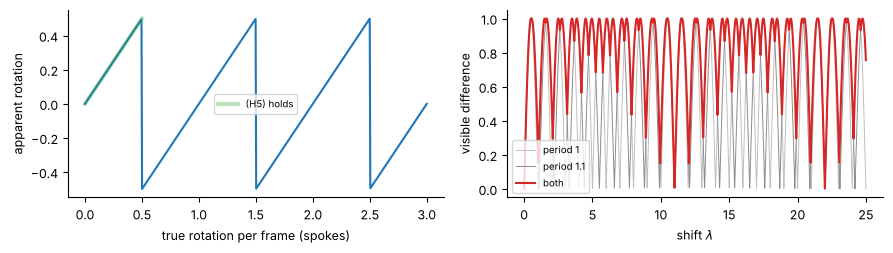

In [13]:
true_rot = np.linspace(0, 3, 600)
apparent = ((true_rot + 0.5) % 1) - 0.5
lam = np.linspace(0, 25, 5000)
r1, r2 = np.abs(np.sin(np.pi*lam/1.0)), np.abs(np.sin(np.pi*lam/1.1))
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6))
ax[0].plot(true_rot, apparent); ax[0].plot([0, 0.5], [0, 0.5], c="C2", lw=3, alpha=.3, label="(H5) holds")
ax[0].set_xlabel("true rotation per frame (spokes)"); ax[0].set_ylabel("apparent rotation"); ax[0].legend(fontsize=7)
ax[1].plot(lam, r1, c="0.75", lw=.7, label="period 1"); ax[1].plot(lam, r2, c="0.55", lw=.7, label="period 1.1")
ax[1].plot(lam, np.maximum(r1, r2), c="C3", label="both"); ax[1].set_xlabel(r"shift $\lambda$"); ax[1].set_ylabel("visible difference"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Hidden capture rates (Prop. 6)

Web-scale video corpora combine recordings at heterogeneous capture rates played back at standard rates. We simulate 2000 snail clips with hidden clocks, $\log\alpha\sim\mathcal N(0.4,0.5^2)$, and measure apparent speeds from the tracks. A learner without reference treats these as natural speeds. The resulting law is shifted by $\mathbb E\log\alpha$ and its variance increased by $\operatorname{Var}\log\alpha$, as stated in Prop. 6.

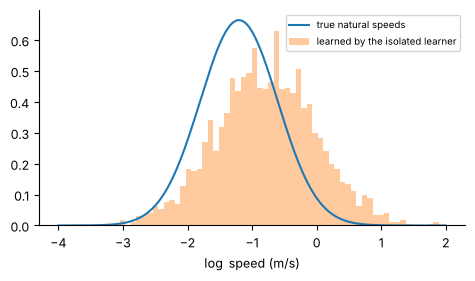

Shift of the learned law: $0.41$ (prediction $\mathbb{E}\log\alpha=0.4$). Variance: $0.59$ (prediction $0.36+0.25$).

In [14]:
Nh = 2000
tk = np.arange(0, 3, 1/FPS)
log_alpha_web = rng.normal(0.4, 0.5, Nh)                 # hidden clocks of a web-like corpus
v_true = np.exp(rng.normal(np.log(0.3), 0.6, Nh))        # natural speeds of the snails
v_apparent = np.array([np.polyfit(tk, snail(np.exp(a)*tk, v)[:, 0] + rng.normal(0, 0.005, len(tk)), 1)[0]
                       for a, v in zip(log_alpha_web, v_true)])
x = np.linspace(-4, 2, 300)
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.plot(x, stats.norm.pdf(x, np.log(0.3), 0.6), label="true natural speeds")
ax.hist(np.log(v_apparent), 60, density=True, alpha=.4, label="learned by the isolated learner")
ax.set_xlabel(r"$\log$ speed (m/s)"); ax.legend(fontsize=7); plt.show()
display(Markdown(f"Shift of the learned law: ${np.log(v_apparent).mean() - np.log(v_true).mean():.2f}$ (prediction $\\mathbb{{E}}\\log\\alpha=0.4$). "
                  f"Variance: ${np.log(v_apparent).var():.2f}$ (prediction ${np.log(v_true).var():.2f}+{log_alpha_web.var():.2f}$)."))

A generator trained in this way would render a "natural" snail at the median of the learned law, here faster than real snails by a factor $e^{0.4}\approx1.5$, although every training clip shows a real snail. This reproduces, in a minimal setting, the inconsistent time scale reported for video generators; conditioning on the playback rate does not remove it.

In [15]:
v_real, v_believed = np.exp(np.median(np.log(v_true))), np.exp(np.median(np.log(v_apparent)))
t = np.arange(0, 3, 1/FPS)
fig, axes = plt.subplots(1, 2, figsize=(7, 1.6))
def update(k):
    for ax, v, title in zip(axes, [v_real, v_believed], [f"real snail ({v_real:.2f} m/s)", f"generated 'natural' snail ({v_believed:.2f} m/s)"]):
        ax.clear(); ax.axis("off"); ax.set_xlim(-0.1, 1.5); ax.set_ylim(-0.1, 0.25)
        ax.plot([-0.1, 1.5], [0, 0], c="0.7"); ax.add_patch(plt.Circle((v*t[k], 0.07), 0.06, color="C1"))
        ax.set_title(title, fontsize=8)
show(fig, update, len(t))

## 8. Identification from co-occurrence (Thm. 7)

Training clips show a walker and a snail under a common hidden clock, drawn independently per clip. No clock is given.

In [16]:
clocks = [0.4, 1.0, 1.8, 0.7]
snail_v = [0.5, 0.35, 0.25, 0.45]
t = np.arange(0, 4, 1/FPS)
fig, axes = plt.subplots(4, 1, figsize=(6, 5))
def update(k):
    for ax, a, v in zip(axes, clocks, snail_v):
        ax.clear(); ax.axis("off"); ax.set_xlim(-0.5, 7.5); ax.set_ylim(-0.15, 1.9); ax.set_aspect("equal")
        ax.plot([-0.5, 7.5], [0, 0], c="0.7")
        s = a*t[k]; draw_walker(ax, 0.5*np.sin(2*np.pi*f_walk(0.5)*s), speed(0.5)*s)
        ax.add_patch(plt.Circle((v*s, 0.08), 0.07, color="C1"))
        ax.set_title(fr"clip with hidden clock $\alpha={a}$", fontsize=8)
show(fig, update, len(t))

For each of 3000 clips we measure two apparent log-paces. For the walker, stride and cadence are estimated from the track and the cadence is compared with that associated with the stride by a regression fitted on the bank; for the snail, the apparent speed is used. Both equal the object's log-pace plus the shared log-clock, so that $\operatorname{Var}\log\alpha=\operatorname{Cov}(Y_A,Y_B)$ and $v_j=\operatorname{Var}Y_j-\operatorname{Cov}(Y_A,Y_B)$. The estimates agree with the true values within sampling error: the procedure identifies, without labels, the variability of the clocks and the rigidity of each class.

| quantity | estimated | true |
|---|---|---|
| $\operatorname{Var}\log\alpha$ | 0.211 | 0.211 |
| $v_A$ (walker) | 0.0059 | 0.0025 |
| $v_B$ (snail) | 0.278 | 0.278 |

Sampling error of these estimates with 3000 clips: about $0.006$.

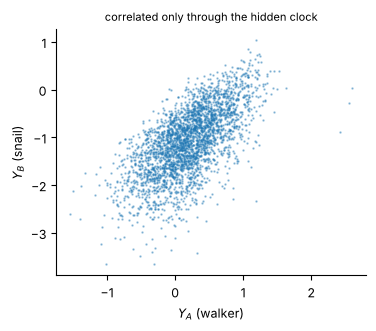

In [17]:
def measure_track(t, x):
    """Stride and cadence of an oscillating track, by least-squares sinusoid fit."""
    def best(freqs):
        S, C = np.sin(2*np.pi*freqs[:, None]*t), np.cos(2*np.pi*freqs[:, None]*t)
        M = np.stack([S, C], -1)
        coef = np.linalg.solve(M.transpose(0, 2, 1) @ M, (M.transpose(0, 2, 1) @ x)[..., None])[..., 0]
        res = ((np.einsum("gkj,gj->gk", M, coef) - x)**2).sum(1)
        return freqs[np.argmin(res)], np.linalg.norm(coef[np.argmin(res)])
    f, A = best(np.linspace(0.2, 8, 400))
    f, A = best(np.linspace(f - 0.03, f + 0.03, 120))
    return A, f

# the association stride -> cadence, learned from the bank (natural speed)
bank_meas = np.array([measure_track(sb[:200], clip[:200, 0]) for clip in BANK["walker"]])
f_learned = np.poly1d(np.polyfit(bank_meas[:, 0], bank_meas[:, 1], 2))

Nc, tk = 3000, np.arange(0, 3, 1/FPS)
log_alpha = rng.normal(0.2, 0.45, Nc)
strides = rng.uniform(0.2, 0.8, Nc)
logw_A = rng.normal(0, 0.05, Nc)                          # walkers: pace nearly fixed by the stride
logw_B = np.log(rng.gamma(4, 0.08, Nc))                   # snails: broad, skewed speeds
YA, YB = np.empty(Nc), np.empty(Nc)
for i in range(Nc):
    a = np.exp(log_alpha[i])
    x = walker(a*np.exp(logw_A[i])*tk, strides[i], rng.uniform(0, 6))[:, 0] + rng.normal(0, 0.005, len(tk))
    A_hat, f_hat = measure_track(tk, x)
    YA[i] = np.log(f_hat/f_learned(A_hat))
    xs = snail(a*tk, np.exp(logw_B[i]))[:, 0] + rng.normal(0, 0.005, len(tk))
    YB[i] = np.log(np.polyfit(tk, xs, 1)[0])
C = np.cov(YA, YB)
display(Markdown(
    "| quantity | estimated | true |\n|---|---|---|\n"
    f"| $\\operatorname{{Var}}\\log\\alpha$ | {C[0,1]:.3f} | {log_alpha.var():.3f} |\n"
    f"| $v_A$ (walker) | {C[0,0]-C[0,1]:.4f} | {logw_A.var():.4f} |\n"
    f"| $v_B$ (snail) | {C[1,1]-C[0,1]:.3f} | {logw_B.var():.3f} |\n\n"
    f"Sampling error of these estimates with {Nc} clips: about ${np.sqrt(C[0,0]*C[1,1]/Nc):.3f}$."))
fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(YA, YB, ".", ms=1.5, alpha=.4); ax.set_xlabel(r"$Y_A$ (walker)"); ax.set_ylabel(r"$Y_B$ (snail)")
ax.set_title("correlated only through the hidden clock", fontsize=8); plt.show()

### Distributions up to a shift

Kotlarski's identity recovers the characteristic functions of $\log\alpha$ and $\log\omega_B$ from the pairs $(Y_A,Y_B)$, up to one shift fixed here by the mean pace of the walker (Thm. 7(2)). The recovered laws match the true ones, whereas the law of apparent speeds is shifted and over-dispersed.

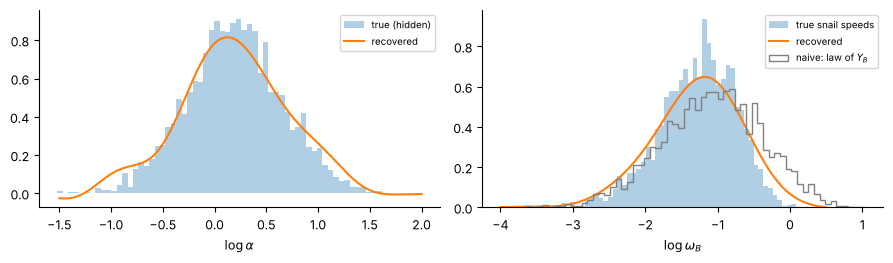

In [18]:
def kotlarski(Y1, Y2, th):
    num = np.array([np.mean(1j*Y1*np.exp(1j*s*Y2)) for s in th])
    den = np.array([np.mean(np.exp(1j*s*Y2)) for s in th])
    g = num/den
    return np.exp(np.concatenate([[0], np.cumsum((g[1:] + g[:-1])/2*np.diff(th))]))
def density(phi, th, x):
    w = np.exp(-2*(th/th.max())**2)
    return np.array([np.trapezoid((phi*w*np.exp(-1j*th*xi)).real, th) for xi in x])/np.pi

th = np.linspace(0, 10, 500)
phi_alpha = kotlarski(YA - 0.0, YB, th)                   # anchor: mean log-pace of the walker is 0
phi_B = np.array([np.mean(np.exp(1j*s*YB)) for s in th])/phi_alpha
tb = th[th <= 6]
xa, xb = np.linspace(-1.5, 2, 300), np.linspace(-4, 0.5, 300)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.7))
ax[0].hist(log_alpha, 60, density=True, alpha=.35, label="true (hidden)"); ax[0].plot(xa, density(phi_alpha, th, xa), label="recovered")
ax[0].set_xlabel(r"$\log\alpha$"); ax[0].legend(fontsize=7)
ax[1].hist(logw_B, 60, density=True, alpha=.35, label="true snail speeds")
ax[1].plot(xb, density(phi_B[:len(tb)], tb, xb), label="recovered")
ax[1].hist(YB, 60, density=True, histtype="step", color="0.5", label=r"naive: law of $Y_B$")
ax[1].set_xlabel(r"$\log\omega_B$"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 9. Reading the clock on a learned object, and along a chain (Cor. 8, Prop. 9)

Once an object has been learned through the clock, how well can the clock be read on it alone, and what happens when it serves in turn as the reference for the next object? These checks use Gaussian laws directly, without clips; the same chain is learned from pixels by a network in Section 5.3 of the report.

Left: the error of the clock read on a learned object follows $v_B\sigma_\alpha^2/(v_B+\sigma_\alpha^2)$ when the object is learned through the shared clock, from exact reading for rigid objects to the prior for elastic ones. An observer that learns the object from apparent paces, as if every video played at natural speed, is bounded below by its squared bias. Right: along a chain of objects of equal rigidity, each calibrated on the previous one with $N$ clips, the bias performs a random walk with standard deviation $\sqrt{2kv_B/N}$ after $k$ steps.

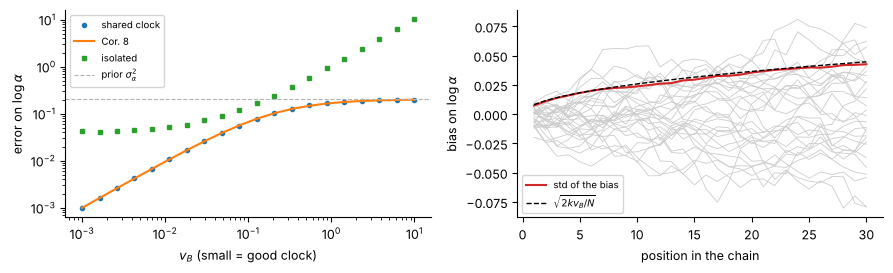

In [22]:
s2, mu_a = 0.45**2, 0.2
vBs = np.logspace(-3, 1, 20)
shared, iso, theory = [], [], []
for vB in vBs:
    la = rng.normal(mu_a, np.sqrt(s2), 20000); lw = rng.normal(-1, np.sqrt(vB), 20000); Yb = lw + la
    shared.append(np.mean((mu_a + s2/(s2 + vB)*(Yb + 1 - mu_a) - la)**2)); iso.append(np.mean((Yb - Yb.mean() - la)**2))
    theory.append(vB*s2/(vB + s2))
vB, reps, steps, n = 0.01, 200, 30, 300
P = np.zeros((reps, steps))
for r_ in range(reps):
    bias = 0.0
    for k in range(steps):
        labels_err = rng.normal(bias, np.sqrt(vB), n)      # clock read on the previous object: its bias and its rigidity
        paces = rng.normal(0, np.sqrt(vB), n)              # the new object's own variation
        bias = labels_err.mean() - paces.mean()            # error on the learned mean pace becomes the new bias
        P[r_, k] = bias
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].loglog(vBs, shared, "o", ms=3, label="shared clock"); ax[0].loglog(vBs, theory, label="Cor. 8")
ax[0].loglog(vBs, iso, "s", ms=3, label="isolated"); ax[0].axhline(s2, c="0.7", ls="--", lw=.8, label=r"prior $\sigma_\alpha^2$")
ax[0].set_xlabel(r"$v_B$ (small = good clock)"); ax[0].set_ylabel(r"error on $\log\alpha$"); ax[0].legend(fontsize=7)
ax[1].plot(np.arange(1, steps+1), P[:30].T, c="0.8", lw=.6); ax[1].plot(np.arange(1, steps+1), P.std(0), c="C3", label="std of the bias")
ax[1].plot(np.arange(1, steps+1), np.sqrt(2*np.arange(1, steps+1)*vB/n), "k--", lw=1, label=r"$\sqrt{2kv_B/N}$")
ax[1].set_xlabel("position in the chain"); ax[1].set_ylabel(r"bias on $\log\alpha$"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Summary

| section | result | illustration |
|---|---|---|
| 1 | Prop. 2 | a faster clock and a faster object produce identical frames |
| 2 | Def. 1 | slowed video and slower object differ for a rigid class, coincide for an elastic one |
| 3 | Def. 2, Prop. 1 | detectability grows with the window; depends on the observed variables and on experience; invariant to the frame rate |
| 4 | Cor. 4 | sequential detection for each class of motion |
| 5 | Prop. 3, Cor. 4(ii) | one rigid object determines the clock of the scene |
| 6 | (H5), Prop. 5 | aliasing, and its reduction by several references |
| 7 | Prop. 6 | hidden capture rates bias learned speeds and generated motion |
| 8 | Thm. 7 | co-occurrence identifies clock variance, rigidity and pace laws without labels |
| 9 | Cor. 8, Prop. 9 | a learned object reads the clock as well as its rigidity allows; along a chain the bias performs a random walk |